In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print(X.head())
print("Dataset shape:", X.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Dataset shape: (150, 4)


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [8]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="average"
)

clusters = model.fit_predict(X_scaled)

X["Cluster"] = clusters

print(X[["Cluster"]].value_counts().sort_index())

Cluster
0          50
1          97
2           3
Name: count, dtype: int64


In [9]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.48


In [10]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", round(score, 3))


Silhouette Score: 0.48


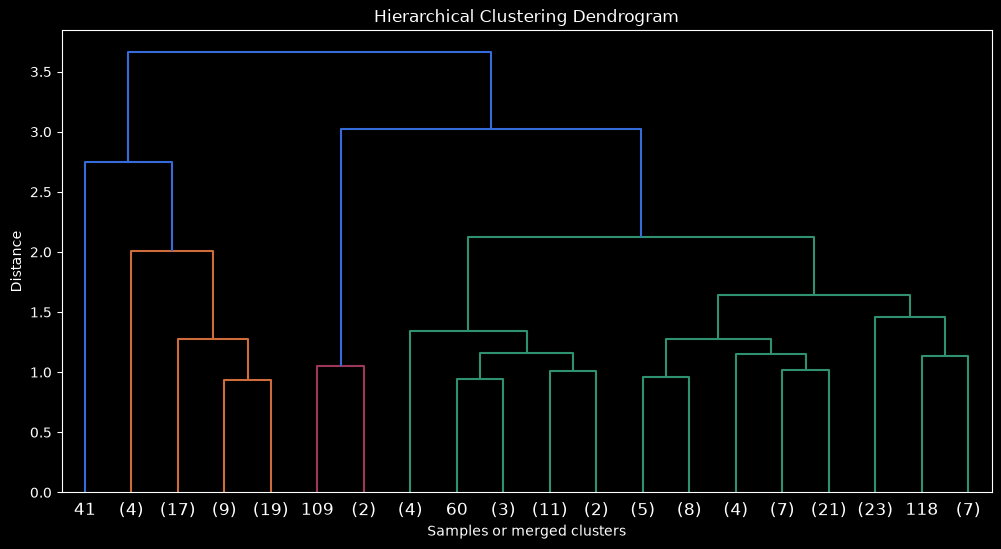

In [11]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="average")

plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=20
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples or merged clusters")
plt.ylabel("Distance")
plt.show()

In [12]:
import pandas as pd

merges = pd.DataFrame({
    "Cluster 1": Z[:, 0].astype(int),
    "Cluster 2": Z[:, 1].astype(int),
    "Merge Distance": Z[:, 2],
    "Points in New Cluster": Z[:, 3].astype(int)
})

print(merges.tail(10).round(3))


     Cluster 1  Cluster 2  Merge Distance  Points in New Cluster
139        282        287           1.273                     45
140        268        280           1.276                     45
141        270        288           1.341                     21
142        279        286           1.455                     31
143        289        292           1.642                     76
144        275        290           2.012                     49
145        291        293           2.123                     97
146         41        294           2.749                     50
147        285        295           3.025                    100
148        296        297           3.660                    150


In [13]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

for k in [2, 3, 4, 5]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="average"
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"K = {k} | Silhouette Score = {score:.3f}")

K = 2 | Silhouette Score = 0.582
K = 3 | Silhouette Score = 0.480
K = 4 | Silhouette Score = 0.407
K = 5 | Silhouette Score = 0.375


In [14]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load Iris dataset
iris = load_iris()
X = iris.data

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Test different values of K
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"K = {k} | Silhouette Score = {score:.3f}")

K = 2 | Silhouette Score = 0.582
K = 3 | Silhouette Score = 0.460
K = 4 | Silhouette Score = 0.387
K = 5 | Silhouette Score = 0.346
K = 6 | Silhouette Score = 0.317
K = 7 | Silhouette Score = 0.320
K = 8 | Silhouette Score = 0.339
K = 9 | Silhouette Score = 0.342
K = 10 | Silhouette Score = 0.352


In [15]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = model.fit_predict(X)

    comparison = pd.crosstab(
        pd.Series(iris.target, name="Actual species"),
        pd.Series(clusters, name="Predicted cluster")
    )

    print(f"\nK = {k}")
    print(comparison)


K = 2
Predicted cluster   0   1
Actual species           
0                   0  50
1                  50   0
2                  50   0

K = 3
Predicted cluster   0   1   2
Actual species               
0                   0  50   0
1                  39   0  11
2                  14   0  36


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import linkage, dendrogram

# Create 15 data points in 3 natural groups
X, y_true = make_blobs(
    n_samples=15,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

print("Dataset shape:", X.shape)
print(X[:5])

Dataset shape: (15, 2)
[[-0.92998481  9.78172086]
 [-2.97261532  8.54855637]
 [ 6.10552761  1.74739338]
 [-8.03062077 -6.50441157]
 [ 4.70740704  0.5484215 ]]


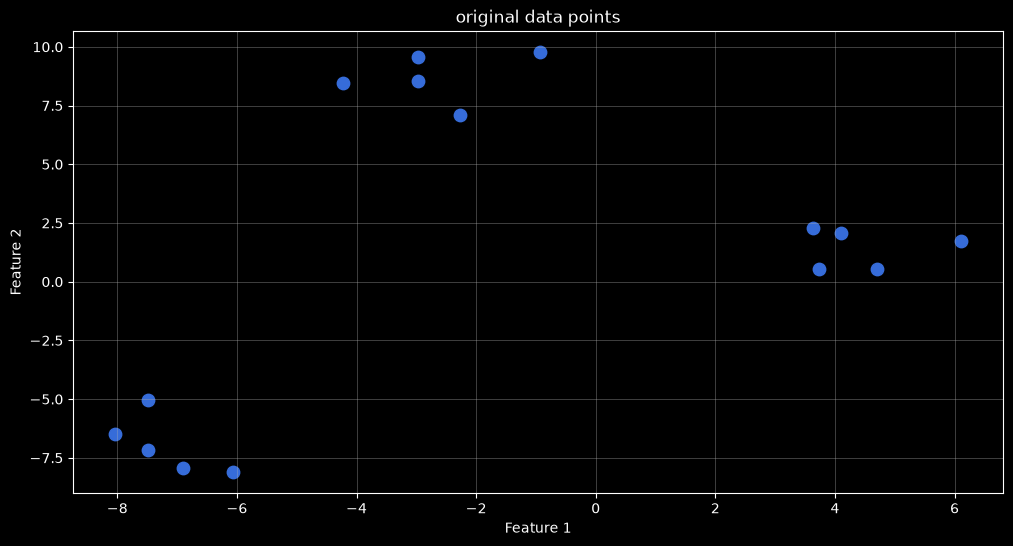

In [2]:
plt.figure(figsize=(12, 6))
plt.scatter(

    X[:,0],
    X[:,1],
    s=80

)

plt.title("original data points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.grid(True)

plt.show()




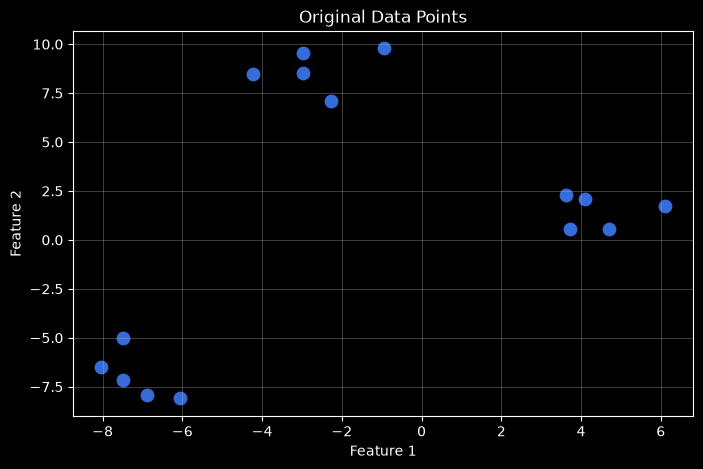

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=80
)

plt.title("Original Data Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()

In [5]:
Z = linkage(X, method="ward")

print("First 5 merges:")
print(Z[:5])



First 5 merges:
[[10.         12.          0.51067098  2.        ]
 [ 5.         13.          0.8518091   2.        ]
 [ 3.          8.          0.86504467  2.        ]
 [ 4.          6.          0.97563165  2.        ]
 [ 1.         14.          1.00830799  2.        ]]


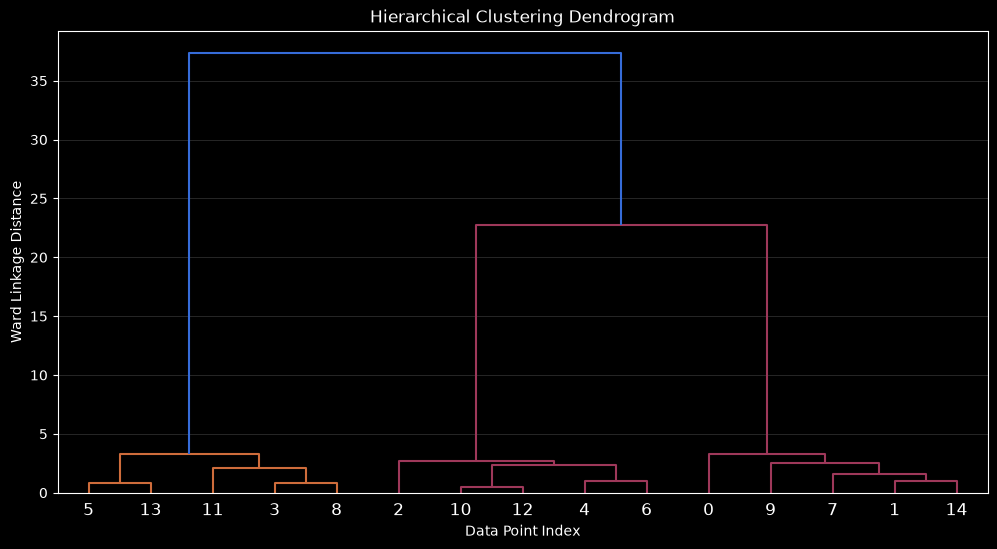

In [6]:
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    labels=np.arange(len(X))
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Point Index")
plt.ylabel("Ward Linkage Distance")
plt.grid(axis="y", alpha=0.3)
plt.show()


